# This is a tutorial for doing the pileup analysis

## Imports

In [1]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import src.analysis as an
import src.dataset as ds
import torch
from scipy.stats import norm
from utility.double_beta_spectrum import pdf_ratio2b
import utility.functions as fn
BASE = "../"
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Choose analysis parameters

In [2]:
meas_name = "000813_20230628T161508"
channel = 5
sampling_rate = 10000
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100) #number of sigma corresponding to the desired acceptance
signal_amp = ds.get_amp_Q_val(channel) #expected amplitude of the signal at the Q-value
#define the time and ratio grid for the analysis
t_min, t_max, N_t = 0, 8e-4, 100
r_min, r_max, N_r = 0., .5, 100
#get the corresponding ratio distribution 
ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
ratio_distribution /= np.mean(ratio_distribution)

window_size = 4096 #size of the window used for the analysis, should be the same as the one used for the NPS computation
n_trials=200 #number of trials for the optimization of the filters

## Load the meanpulse and Noise power spectrum
if they are not already compute, look build_meanpulses.py and build_NPS.py to compute them

In [3]:
#load the meanpulse
meanpulse = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_mean.npy")
if len(meanpulse) > window_size:
    meanpulse = meanpulse[np.argmax(meanpulse) - window_size//2 : np.argmax(meanpulse) + window_size//2]
#load the NPS
nps = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
nps *= (8. / 3.)  # Adjust for Hann window effect

## Compute the optimal filter

In [4]:
S, w, H_unit = an.compute_H(meanpulse, nps, np.hanning,sampling_rate=sampling_rate)

In [5]:
sigma_analytic = an.compute_sigma_OF(S, nps)
print(f"Analytic sigma: {sigma_analytic*1000:.4f} mV")
print(f"signal_amp: {signal_amp*1000:.4f} mV")
print(f"SNR: {signal_amp / sigma_analytic:.2f}")

Analytic sigma: 0.0802 mV
signal_amp: 11.3203 mV
SNR: 141.08


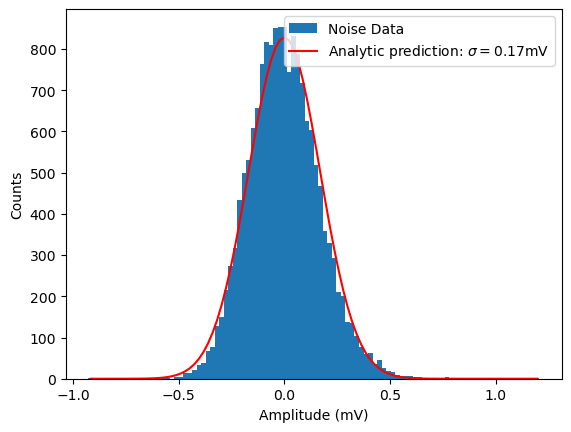

In [41]:
data = dataset.data.cpu().numpy()[std < 0.00023]
data -= np.mean(data, axis=1, keepdims=True)
amp = np.mean(np.fft.fft(data*np.hanning(window_size),axis=1)*H_unit, axis=1).real*1000
_,bins,_=plt.hist(amp, bins=100,label = "Noise Data")
bin_centers = (bins[:-1] + bins[1:]) / 2
plt.plot(bin_centers, norm.pdf(bin_centers, scale=sigma_analytic*1000)*len(amp)*(bins[1]-bins[0]), color="red", label=f"Analytic prediction: $\sigma = {sigma_analytic*1000:.2f}$mV")
plt.legend()
plt.ylabel("Counts")
plt.xlabel("Amplitude (mV)")
plt.show()

## Convert the relevant arrays to torch tensors and move them to the appropriate device (CPU or GPU)

In [6]:
S_torch = torch.tensor(S, dtype=torch.cfloat, device=device)
H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat, device=device)
w_torch = torch.tensor(w, dtype=torch.cfloat, device=device)
nps_torch = torch.tensor(nps, dtype=torch.cfloat, device=device)
signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32, device=device)
t_torch = torch.linspace(t_min, t_max, N_t, dtype=torch.cfloat, device=device)
r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat, device=device)
ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat, device=device)

## Optimize the filters for minimal misidentification rate (M_value)

In [36]:
f1_t, f2_t, M_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch,
                                           signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma, 
                                           activation_fct = torch.abs,
                                           f1_init = None, f2_init = None,
                                           n_trials=300, use_interp = True, verbose=True)


Step 0: J = 0.827887
Step 10: J = 0.500130
Step 20: J = 0.388789
Step 30: J = 0.345381
Step 40: J = 0.321153
Step 50: J = 0.305138
Step 60: J = 0.293931
Step 70: J = 0.285883
Step 80: J = 0.280035
Step 90: J = 0.275672
Step 100: J = 0.272319
Step 110: J = 0.269695
Step 120: J = 0.267613
Step 130: J = 0.265950
Step 140: J = 0.264617
Step 150: J = 0.263539
Step 160: J = 0.262668
Step 170: J = 0.261958
Step 180: J = 0.261384
Step 190: J = 0.260922
Step 200: J = 0.260547
Step 210: J = 0.260250
Step 220: J = 0.260018
Step 230: J = 0.259836
Step 240: J = 0.259701
Step 250: J = 0.259604
Step 260: J = 0.259536
Step 270: J = 0.259497
Step 280: J = 0.259470
Step 290: J = 0.259464
Final: J = 0.259463


## Save the results

In [40]:
f1_opt,f2_opt = f1_t.cpu().numpy(), f2_t.cpu().numpy()
np.save(f"{BASE}/outputs/training_Ms/channel_{channel}/M_{int(acceptance * 100):d}_RUN14_meas204", np.array(M_values))
np.save(f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance * 100):d}_RUN14_meas204",np.array([f1_opt, f2_opt]))

In [7]:

func = np.load(f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance * 100):d}.npy")
f1_opt, f2_opt = func[0], func[1]
f1_t, f2_t = torch.tensor(f1_opt, dtype=torch.cfloat, device=device), torch.tensor(f2_opt, dtype=torch.cfloat, device=device)

# BI estimation
A proxi for the BI can be optained from the Misidentification rate (M_value) 

In [39]:
BI_estimate = M_values[-1] * fn.K #Here K is a constant that depends on crystal size, Mo-2b2n decay rate, maximum delay studied,...
BI_estimate

6.890690739095343e-05

# Compute the Background Index using injected pulses
If enough statistics is available, the BI can be computed directly from the injected pulse datasets, by applying the optimized filters and counting the number of misidentified pileup events.

## Load the dataset
path_pos_single and path_pos_pileup are the paths to the position files for the single pulse and pileup datasets, respectively. They contain the relevent informations for the injection (position in the raw file to inject pulse , amplitudes, delay, smearing,...). Those data are created by montecarlo from IJClab code.

In [8]:
#load the pulse to be injected
meanpulse_inj = np.load(f"{BASE}/outputs/meanpulses_build/pos_pulses_rawdata/average_pulse_channel{channel}.npy")
#load the single pulse dataset
dataset_single_name = "pup_n1-d0_000813_20230628T161508"
file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
                                                  specific_subdir="RUN9_pulse_injected_new/")
data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, window_size,
                                                   pulse=meanpulse_inj,
                                                   n_windows=5999, win_shift=0)
#load the pileup pulse dataset
dataset_pileup_name = "pup_n1-d8_000813_20230628T161508"
file_path_pileup, path_pos_pileup = ds.find_files(meas_name, dataset_pileup_name, channel,
                                                  specific_subdir="RUN9_pulse_injected_new/")
data_pileup = ds.CachedBinaryDataset_withgenerated(file_path_pileup, path_pos_pileup, window_size,
                                                   pulse=meanpulse_inj,
                                                   n_windows=5999, win_shift=0)

(5999, 3)
(5999, 7)


## Compute the Background Index

In [15]:
BI, rp, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI_torch(
            data_pileup,
            data_single,
            acceptance,
            H_unit_torch,
            f1_t,
            f2_t,
            window_fct = np.hanning,
            compute_uncertainty = False,
            batch_size = 2048,
            use_loader = False,
            full_output = True
        )
print(BI*1e5, rp)
plt.hist(PSD_single, bins=100,range=(0.85,1.02), alpha=0.5, label="Single pulse", color="red")
plt.hist(PSD_pileup, bins=100,range=(0.85,1.02), alpha=0.5, label="Pileup pulse", color="blue")
cut = np.percentile(PSD_single,(1-acceptance)*100)
plt.axvline(cut, color="black", linestyle="--", label="Threshold")

KeyboardInterrupt: 

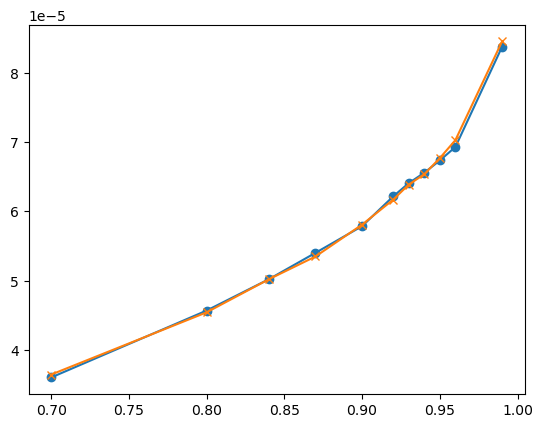

In [14]:
import pandas as pd
acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]

data_acc = pd.read_csv(f"{BASE}/outputs/BI_acceptance_study.csv")
BIs = []
for acceptance in acceptances:
    cut = np.percentile(PSD_single,(1-acceptance)*100)
    rp = float(torch.sum(PSD_pileup < cut) / len(PSD_pileup))
    BI = fn.K * (1.0 - rp)
    BIs.append(BI)
plt.plot(acceptances, BIs, marker='o', label='Computed BI')
plt.plot(data_acc.loc[data_acc['channel']==channel,'acceptance'], data_acc.loc[data_acc['channel']==channel,'BI'], marker='x', label='Saved BI')